In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load and Inspect the csv file, 

In [2]:

# Load the CSV file into a DataFrame

In [3]:
data_path = r"C:\Users\nnenn\OneDrive\Full Stack Data Science Practise\Live Classes\Python\lumenpay_transactions.csv"

lumen_df = pd.read_csv(data_path)

In [4]:
lumen_df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,398,PAYMENT,14055.78,C1797200575,159180.00,145124.22,M1160381986,0.00,0.00,0,0
1,182,CASH_OUT,180339.33,C700363449,5318.00,0.00,C1953400814,0.00,180339.33,0,0
2,134,CASH_IN,30487.29,C712454949,12380.00,42867.29,C603302194,2405494.70,2375007.41,0,0
3,401,PAYMENT,26549.72,C648332042,0.00,0.00,M361318237,0.00,0.00,0,0
4,331,CASH_IN,486453.98,C59362593,5894087.86,6380541.85,C574749985,3917145.47,3430691.48,0,0


In [5]:
# To check number of rows, column and general informations

print("Rows and columns:", lumen_df.shape)  # to check the array size/shape
print("---------------------------------------------------")
lumen_df.info()

Rows and columns: (25000, 11)
---------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            25000 non-null  int64  
 1   type            25000 non-null  object 
 2   amount          25000 non-null  float64
 3   nameOrig        25000 non-null  object 
 4   oldbalanceOrg   25000 non-null  float64
 5   newbalanceOrig  25000 non-null  float64
 6   nameDest        25000 non-null  object 
 7   oldbalanceDest  25000 non-null  float64
 8   newbalanceDest  25000 non-null  float64
 9   isFraud         25000 non-null  int64  
 10  isFlaggedFraud  25000 non-null  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 2.1+ MB


#### # Meta data view

In [6]:
# Summary statistics for the number columns

lumen_df.head(20)  # First 20 rows

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,398,PAYMENT,14055.78,C1797200575,159180.00,145124.22,M1160381986,0.00,0.00,0,0
1,182,CASH_OUT,180339.33,C700363449,5318.00,0.00,C1953400814,0.00,180339.33,0,0
2,134,CASH_IN,30487.29,C712454949,12380.00,42867.29,C603302194,2405494.70,2375007.41,0,0
3,401,PAYMENT,26549.72,C648332042,0.00,0.00,M361318237,0.00,0.00,0,0
4,331,CASH_IN,486453.98,C59362593,5894087.86,6380541.85,C574749985,3917145.47,3430691.48,0,0
5,179,PAYMENT,3042.33,C1639611674,0.00,0.00,M161292316,0.00,0.00,0,0
6,351,PAYMENT,10907.38,C1910448239,0.00,0.00,M1991934004,0.00,0.00,0,0
7,382,PAYMENT,7979.11,C1404432659,137560.00,129580.89,M91817794,0.00,0.00,0,0
8,42,CASH_OUT,55030.05,C476068221,11324.00,0.00,C467038767,0.00,55030.05,0,0
9,306,PAYMENT,16920.93,C1735846754,22591.00,5670.07,M1440368964,0.00,0.00,0,0


In [7]:

#lumen_df.sample(10) # To see 10 random sample of data points to see the variability
lumen_df.sample(15, random_state=42)  #42 locks it across & prevents it from changing

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6868,177,PAYMENT,2506.10,C2061032047,0.00,0.00,M1266999696,0.00,0.00,0,0
24016,185,CASH_OUT,138625.36,C332535760,97313.00,0.00,C361852756,20797.78,159423.14,0,0
9668,163,PAYMENT,7150.34,C942673453,21028.00,13877.66,M1757761298,0.00,0.00,0,0
13640,558,TRANSFER,209829.57,C955753523,209829.57,0.00,C1528787754,0.00,0.00,1,0
14018,354,TRANSFER,331743.49,C746822304,77742.45,0.00,C409798595,2148802.40,2480545.89,0,0
7488,407,CASH_OUT,235417.96,C1152594648,0.00,0.00,C1209957098,5219589.33,5455007.30,0,0
5804,355,CASH_IN,9709.31,C1293835534,896553.77,906263.08,C210179948,960797.59,951088.27,0,0
12909,38,CASH_IN,255228.37,C2007724197,21044.00,276272.37,C1994288298,0.00,0.00,0,0
3386,203,CASH_IN,11603.73,C526179419,7370337.94,7381941.67,C169902127,160508.41,148904.69,0,0
9567,374,CASH_OUT,423406.78,C2121118648,10082.00,0.00,C1697531913,18605036.39,19028443.17,0,0


In [8]:
# To understand what all the numerical data is all about
lumen_df.describe().T.round(2)  # .T.round(2) helps to Transpose & round the data to 2 decimal place

,count,mean,std,min,25%,50%,75%,max
step,25000.0,245.04,143.21,1.0,156.0,249.00,346.00,7.420000e+02
amount,25000.0,200648.09,680863.28,0.0,13580.3,76826.77,212603.52,3.619687e+07
oldbalanceOrg,25000.0,802693.90,2838465.26,0.0,0.0,14044.50,111659.75,4.958504e+07
newbalanceOrig,25000.0,802035.90,2847350.62,0.0,0.0,0.00,131216.34,3.958504e+07
oldbalanceDest,25000.0,1076237.00,3256803.58,0.0,0.0,122385.22,929433.08,1.783038e+08
newbalanceDest,25000.0,1211776.95,3540280.23,0.0,0.0,207051.47,1114826.58,2.145007e+08
isFraud,25000.0,0.02,0.12,0.0,0.0,0.00,0.00,1.000000e+00
isFlaggedFraud,25000.0,0.00,0.01,0.0,0.0,0.00,0.00,1.000000e+00


In [9]:
#To count and sum how many null values in each column

lumen_df.isna().sum()


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [10]:
lumen_df.duplicated().sum()     # Sum of Duplicated rows

np.int64(0)

In [11]:
lumen_df.nunique()  # Number of unique occurences in our data

step                537
type                  5
amount            24944
nameOrig          25000
oldbalanceOrg     15419
newbalanceOrig    10475
nameDest          24530
oldbalanceDest    14244
newbalanceDest    15317
isFraud               2
isFlaggedFraud        2
dtype: int64

In [12]:
# How many transactions of each type?
# value_counts() works well with groupby()
lumen_df["type"].value_counts()  # Count  each individual columns e.g  in 'type'

type
CASH_OUT    8950
PAYMENT     8387
CASH_IN     5256
TRANSFER    2260
DEBIT        147
Name: count, dtype: int64

In [13]:
lumen_df.groupby("step")["type"].value_counts()

step  type    
1     PAYMENT     4
      CASH_IN     2
      TRANSFER    1
2     PAYMENT     2
      CASH_IN     1
                 ..
735   CASH_OUT    1
736   CASH_OUT    1
      TRANSFER    1
741   TRANSFER    1
742   CASH_OUT    1
Name: count, Length: 1671, dtype: int64

In [14]:
lumen_df.groupby(["type", "step"])["amount"].sum()  # Grouping by multiple columns(type, step, sum of amount)

type      step
CASH_IN   1       1385600.40
          2        188118.26
          3        254872.55
          4         82172.42
          6        392836.67
                     ...    
TRANSFER  727      276298.49
          731      521502.75
          732      311832.17
          736     3912252.81
          741       62297.18
Name: amount, Length: 1671, dtype: float64

In [15]:
# Note: Grouping by multiple columns and more than one aggregate, 
# We pass the columns  and aggregates to be used as a list, e.g.,


lumen_df.groupby(["type", "step"])["amount"].agg(['mean', 'sum']).round(2)

mean         sum
type     step                        
CASH_IN  1      692800.20  1385600.40
         2      188118.26   188118.26
         3      254872.55   254872.55
         4       82172.42    82172.42
         6      130945.56   392836.67
...                   ...         ...
TRANSFER 727    276298.49   276298.49
         731    260751.38   521502.75
         732    311832.17   311832.17
         736   3912252.81  3912252.81
         741     62297.18    62297.18

[1671 rows x 2 columns]

### Cleaning Data

In [16]:
lumen_df.columns   # To list out all the columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [17]:
# Renaming the columns/headers

df = lumen_df.rename(columns={
    "step": "hour_number", 
    "type": "trans_type", 
    "nameOrig": "sender", 
    "oldbalanceOrg": "old_sender_balance",
    "newbalanceOrig": "new_sender_balance",
    "nameDest": "receiver",
    "oldbalanceDest": "old_receiver_balance",
    "newbalanceDest": "new_receiver_balance",
    "isFraud": "is_fraud",
    "isFlaggedFraud": "is_flagged",
})

df.columns

Index(['hour_number', 'trans_type', 'amount', 'sender', 'old_sender_balance',
       'new_sender_balance', 'receiver', 'old_receiver_balance',
       'new_receiver_balance', 'is_fraud', 'is_flagged'],
      dtype='object')

In [18]:
# Cleaning and standardising the 'trans_type' column data
# .str --- converts it to a string


df['trans_type'] = df['trans_type'].str.replace("_", " ").str.title()    # Replace _ with a space and standardize

In [19]:
# Another method
# When replacing multiple things, you pass them as a dictionary, e.g

# df['trans_type'] = df['trans_type'].str.replace({"Cashout": "Cash Out", "Cashin": "Cash In"}).str.title()

In [20]:
df['trans_type'].unique()

array(['Payment', 'Cash Out', 'Cash In', 'Transfer', 'Debit'],
      dtype=object)

In [2]:
# inplace=True helps to effect the changes in the original data Frame

# df.drop(columns='trans_type', inplace=True)


### Duplicates and missing values

In [22]:
df.sample(10, random_state=3)

,hour_number,trans_type,amount,sender,old_sender_balance,new_sender_balance,receiver,old_receiver_balance,new_receiver_balance,is_fraud,is_flagged
11758,395,Cash In,53471.18,C302466644,11618749.99,11672221.17,C1013872351,2903006.47,2960011.05,0,0
9342,371,Cash Out,61134.11,C133435740,0.00,0.00,C1008587490,652878.75,714012.87,0,0
13245,305,Cash Out,55199.31,C1737225675,11124.00,0.00,C1691617672,1036184.37,1091383.67,0,0
10648,180,Cash In,373879.19,C1631778568,4464356.90,4838236.08,C390483514,870337.04,496457.86,0,0
15786,138,Payment,22845.47,C1694314474,109915.00,87069.53,M1507373659,0.00,0.00,0,0
15178,7,Payment,3904.07,C1859349571,2562.00,0.00,M59295878,0.00,0.00,0,0
8504,140,Payment,7966.00,C122579126,0.00,0.00,M961604735,0.00,0.00,0,0
14524,298,Payment,15375.69,C1549692406,0.00,0.00,M1663816925,0.00,0.00,0,0
3451,280,Payment,2080.46,C568783937,342817.04,340736.59,M670981864,0.00,0.00,0,0
24819,352,Transfer,2680.39,C502443681,0.00,0.00,C1279260145,342604.69,345285.08,0,0


In [23]:
# Cleaning by adding 2 new columns: 'sender_type' & 'receiver_type'
# Separating the customers from the Merchants
# In the 'sender' column, where it starts with "C", classify it as 'Customer'; otherwise, as 'Merchant'
# same process in the 'receiver' column

df["sender_type"] = np.where(df["sender"].str.startswith("C"), "Customer", "Merchant")
df["receiver_type"] = np.where(df["receiver"].str.startswith("C"), "Customer", "Merchant")

In [24]:
df

,hour_number,trans_type,amount,sender,old_sender_balance,new_sender_balance,receiver,old_receiver_balance,new_receiver_balance,is_fraud,is_flagged,sender_type,receiver_type
0,398,Payment,14055.78,C1797200575,159180.00,145124.22,M1160381986,0.00,0.00,0,0,Customer,Merchant
1,182,Cash Out,180339.33,C700363449,5318.00,0.00,C1953400814,0.00,180339.33,0,0,Customer,Customer
2,134,Cash In,30487.29,C712454949,12380.00,42867.29,C603302194,2405494.70,2375007.41,0,0,Customer,Customer
3,401,Payment,26549.72,C648332042,0.00,0.00,M361318237,0.00,0.00,0,0,Customer,Merchant
4,331,Cash In,486453.98,C59362593,5894087.86,6380541.85,C574749985,3917145.47,3430691.48,0,0,Customer,Customer
...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,514,Transfer,4269063.59,C2145382157,155884.00,0.00,C1781058755,296293.31,4565356.90,0,0,Customer,Customer
24996,308,Payment,9754.17,C1160875468,0.00,0.00,M930892729,0.00,0.00,0,0,Customer,Merchant
24997,348,Payment,14322.14,C1156608160,0.00,0.00,M755912935,0.00,0.00,0,0,Customer,Merchant
24998,187,Cash Out,260779.05,C439085922,9997.00,0.00,C841741703,0.00,260779.05,0,0,Customer,Customer


In [25]:
# To check if any 'sender_type' is a 'Merchant'

df[df["sender_type"] == 'Merchant']  # This returns empty columns

,hour_number,trans_type,amount,sender,old_sender_balance,new_sender_balance,receiver,old_receiver_balance,new_receiver_balance,is_fraud,is_flagged,sender_type,receiver_type


In [26]:
# Repeating same for the 'receiver_type'

df[df['receiver_type'] == 'Merchant']

,hour_number,trans_type,amount,sender,old_sender_balance,new_sender_balance,receiver,old_receiver_balance,new_receiver_balance,is_fraud,is_flagged,sender_type,receiver_type
0,398,Payment,14055.78,C1797200575,159180.0,145124.22,M1160381986,0.0,0.0,0,0,Customer,Merchant
3,401,Payment,26549.72,C648332042,0.0,0.00,M361318237,0.0,0.0,0,0,Customer,Merchant
5,179,Payment,3042.33,C1639611674,0.0,0.00,M161292316,0.0,0.0,0,0,Customer,Merchant
6,351,Payment,10907.38,C1910448239,0.0,0.00,M1991934004,0.0,0.0,0,0,Customer,Merchant
7,382,Payment,7979.11,C1404432659,137560.0,129580.89,M91817794,0.0,0.0,0,0,Customer,Merchant
...,...,...,...,...,...,...,...,...,...,...,...,...,...
24989,356,Payment,9715.37,C784873259,0.0,0.00,M29285500,0.0,0.0,0,0,Customer,Merchant
24992,168,Payment,2535.07,C1273017224,169948.0,167412.93,M1818154667,0.0,0.0,0,0,Customer,Merchant
24993,376,Payment,4870.63,C1030812617,0.0,0.00,M242996747,0.0,0.0,0,0,Customer,Merchant
24996,308,Payment,9754.17,C1160875468,0.0,0.00,M930892729,0.0,0.0,0,0,Customer,Merchant


In [27]:
# Checking the sum of balances of the subset 'merchants' in the 'receiver_type' column 

df[df["receiver_type"] == "Merchant"].groupby("receiver_type")[[ "old_receiver_balance", "new_receiver_balance"]].sum()

,old_receiver_balance,new_receiver_balance
receiver_type,,
Merchant,0.0,0.0


In [28]:
# Replacing every occurrence of 0.0 in the merchant's balances with  np.nan, so that 
# when we calculate the average, it does not skew/affect the result

df[["old_receiver_balance", "new_receiver_balance"]] = df[["old_receiver_balance", "new_receiver_balance"]].replace(0.0, np.nan)

In [29]:
# Filtering to see the effect of np.nan used;

df[df['receiver_type'] == 'Merchant']

,hour_number,trans_type,amount,sender,old_sender_balance,new_sender_balance,receiver,old_receiver_balance,new_receiver_balance,is_fraud,is_flagged,sender_type,receiver_type
0,398,Payment,14055.78,C1797200575,159180.0,145124.22,M1160381986,NaN,NaN,0,0,Customer,Merchant
3,401,Payment,26549.72,C648332042,0.0,0.00,M361318237,NaN,NaN,0,0,Customer,Merchant
5,179,Payment,3042.33,C1639611674,0.0,0.00,M161292316,NaN,NaN,0,0,Customer,Merchant
6,351,Payment,10907.38,C1910448239,0.0,0.00,M1991934004,NaN,NaN,0,0,Customer,Merchant
7,382,Payment,7979.11,C1404432659,137560.0,129580.89,M91817794,NaN,NaN,0,0,Customer,Merchant
...,...,...,...,...,...,...,...,...,...,...,...,...,...
24989,356,Payment,9715.37,C784873259,0.0,0.00,M29285500,NaN,NaN,0,0,Customer,Merchant
24992,168,Payment,2535.07,C1273017224,169948.0,167412.93,M1818154667,NaN,NaN,0,0,Customer,Merchant
24993,376,Payment,4870.63,C1030812617,0.0,0.00,M242996747,NaN,NaN,0,0,Customer,Merchant
24996,308,Payment,9754.17,C1160875468,0.0,0.00,M930892729,NaN,NaN,0,0,Customer,Merchant


### Creating New columns to help solve Business problems

In [30]:
# Creating value bands using the 'amounts' column
# First, check the variability of the numerical data in 'amounts' using a NumPy array

#Pulling and converting 'amounts' to numpy array
amounts = df['amount'].to_numpy()
print(type(amounts), amounts.shape)  #To confirm Type and shape of array

print("Mean : ", round(np.mean(amounts)))     #This calculates the average value of amounts
print("Median : ", round(np.median(amounts))) 
print("Standard deviation: ", round(np.std(amounts)))  #To check how spread out the data is w.r.t mean/average

<class 'numpy.ndarray'> (25000,)
Mean :  200648
Median :  76827
Standard deviation:  680850


The mean is much bigger than the median, so a **few very large transactions pull the average up**.
The median is the best representation of a typical value in 'amount' column

In [31]:
# Creating value bands using the 'amounts' column
# Extracting 'high_value_transactions' from normal transactions: focus is on the top 10

p90 = np.percentile(amounts, 90)  
print("90% of transactions are below : ", round(p90))

#Creating a new column 'value_band'
df['value_band'] = np.where(df['amount'] > p90, 'High value', 'Normal')
df['value_band'].value_counts()

90% of transactions are below :  378094


value_band
Normal        22500
High value     2500
Name: count, dtype: int64

In [32]:
# Extracting the actual hours & days of transactions from 'hour_number' column into new columns

df['hour_of_day'] = df['hour_number'] % 24  # Calculate the Remainder after every 24 hours in a day.

df['day'] = (df['hour_number'] - 1) // 24 + 1  
"""
 '-1' Adjusts the hours so counting starts from zero.
 After, floor division // 24 hours of each day
+ 1 — Ensures the day numbering starts at Day 1 instead of Day 0. """

df[['hour_number', 'day', 'hour_of_day']].head()



,hour_number,day,hour_of_day
0,398,17,14
1,182,8,14
2,134,6,14
3,401,17,17
4,331,14,19


In [33]:
# Grouping hours into time_bands

hour = df['hour_of_day']
conditions = [hour <= 8, hour <= 20]
labels = ['Night (00-08)', 'Daytime (09-20)']

#np.where is applied ("if this, then A, else B"). 
#np.select is the same principle, but is used when there are more than two outcomes in consideration.

df['time_band'] = np.select(conditions, labels, default="Late evening (21-23)")
df['time_band'].value_counts()


time_band
Daytime (09-20)         21994
Late evening (21-23)     2287
Night (00-08)             719
Name: count, dtype: int64

### Answering Business questions
How big was the month, and which transaction types carry the value?

In [34]:
# Getting unique transaction types

df['trans_type'].unique()

array(['Payment', 'Cash Out', 'Cash In', 'Transfer', 'Debit'],
      dtype=object)

In [35]:
# Calc & sort very large transfers: (type is Transfer AND amount is above 1,000,000)

big_transfers = df[(df['trans_type'] == 'Transfer') & (df['amount'] > 1_000_000)]

print("Total number of large Transfers above £ 1,000,000: ", len(big_transfers))

print("Top 5 largest Transfers:")
big_transfers.sort_values('amount', ascending=False).head(5)


Total number of large Transfers above £ 1,000,000:  563
Top 5 largest Transfers:


,hour_number,trans_type,amount,sender,old_sender_balance,new_sender_balance,receiver,old_receiver_balance,new_receiver_balance,is_fraud,is_flagged,sender_type,receiver_type,value_band,hour_of_day,day,time_band
9366,303,Transfer,36196873.65,C1172583796,0.0,0.0,C2120613885,1.783038e+08,2.145007e+08,0,0,Customer,Customer,High value,15,13,Daytime (09-20)
10618,301,Transfer,23097400.70,C1041914844,0.0,0.0,C1390793768,2.802641e+07,5.112381e+07,0,0,Customer,Customer,High value,13,13,Daytime (09-20)
20663,303,Transfer,19759982.50,C1386529033,0.0,0.0,C1084475085,2.853252e+07,4.829250e+07,0,0,Customer,Customer,High value,15,13,Daytime (09-20)
22097,303,Transfer,17222423.25,C1451713075,0.0,0.0,C1234980461,3.137869e+07,4.860111e+07,0,0,Customer,Customer,High value,15,13,Daytime (09-20)
3752,284,Transfer,16625126.92,C2146002726,0.0,0.0,C1246973714,2.980453e+07,4.642966e+07,0,0,Customer,Customer,High value,20,12,Daytime (09-20)


In [36]:
# Calc for Other Transaction types

transactions = df[df['trans_type'].isin(['Cash In', 'Cash Out'])]

# No of Cash In and Cash Out transactions
print("Cash In & Cash Out:", len(transactions))

# For Debit transactions
other_transactions = df[df['trans_type'] == 'Debit']
print("Count of 'Debit' transactions: ", len(other_transactions))


print("Smallest 3 payments:")
df[df['trans_type'] == 'Payment'].nsmallest(3, 'amount') #.nsmallest- Return the first n rows(n =3) with the smallest interger

Cash In & Cash Out: 14206
Count of 'Debit' transactions:  147
Smallest 3 payments:


,hour_number,trans_type,amount,sender,old_sender_balance,new_sender_balance,receiver,old_receiver_balance,new_receiver_balance,is_fraud,is_flagged,sender_type,receiver_type,value_band,hour_of_day,day,time_band
24363,203,Payment,3.41,C499957973,45452.0,45448.59,M1619725328,NaN,NaN,0,0,Customer,Merchant,Normal,11,9,Daytime (09-20)
1106,267,Payment,7.89,C466530834,0.0,0.00,M1875151791,NaN,NaN,0,0,Customer,Merchant,Normal,3,12,Night (00-08)
21364,322,Payment,8.68,C1992355356,85156.0,85147.32,M816703798,NaN,NaN,0,0,Customer,Merchant,Normal,10,14,Daytime (09-20)


### Joining a Lookup table with 'merge'

In [37]:
# The product team sent a small lookup table that groups transaction types into product lines
lookup = pd.DataFrame({
    "trans_type": ["Cash In", "Cash Out", "Payment", "Transfer", "Debit"],
    "product_line": ["Cash services", "Cash services", "Merchant payments",
                     "Person to person", "Bank withdrawals"],
})

# Joining the 'lookup' table to 'df' table

df = df.merge(lookup, on='trans_type', how='left')
df['product_line'].value_counts()

product_line
Cash services        14206
Merchant payments     8387
Person to person      2260
Bank withdrawals       147
Name: count, dtype: int64

### Transaction Summary: Using Groupby

In [38]:
summary = df.groupby(df['trans_type']).agg(
    Total_transactions=('amount', 'count'),
    Total_value=('amount', 'sum'),
    Typical_amount=('amount', 'median')
)

# Adding a new column 'value_share_pct' and sorting it in descending order
summary['Value_share_pct'] = (summary['Total_value'] / summary['Total_value'].sum() * 100).round(1) 

summary.sort_values('Total_value', ascending=False).round()

,Total_transactions,Total_value,Typical_amount,Value_share_pct
trans_type,,,,
Transfer,2260,2.217782e+09,488546.0,44.0
Cash Out,8950,1.792601e+09,146385.0,36.0
Cash In,5256,8.944295e+08,143916.0,18.0
Payment,8387,1.105600e+08,9640.0,2.0
Debit,147,8.297780e+05,2672.0,0.0


In [39]:
#095a51, #a01810

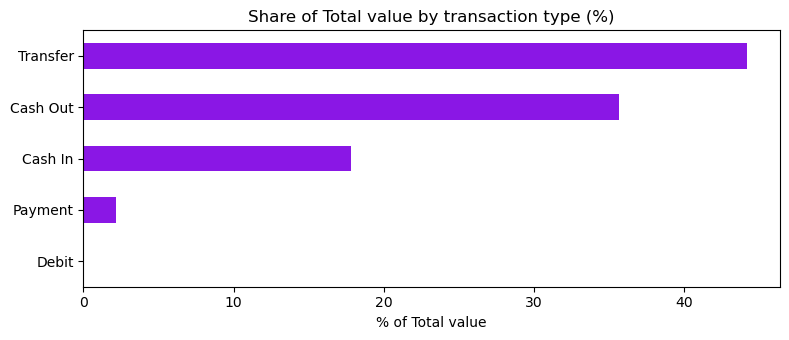

In [40]:
# Ploting a bar chart of summary table

share = summary['Value_share_pct'].sort_values()
share.plot(kind='barh', color='#8a17e5', figsize=(8, 3.5))
plt.title('Share of Total value by transaction type (%)')
plt.xlabel('% of Total value')
plt.ylabel('')
plt.tight_layout()
plt.show()

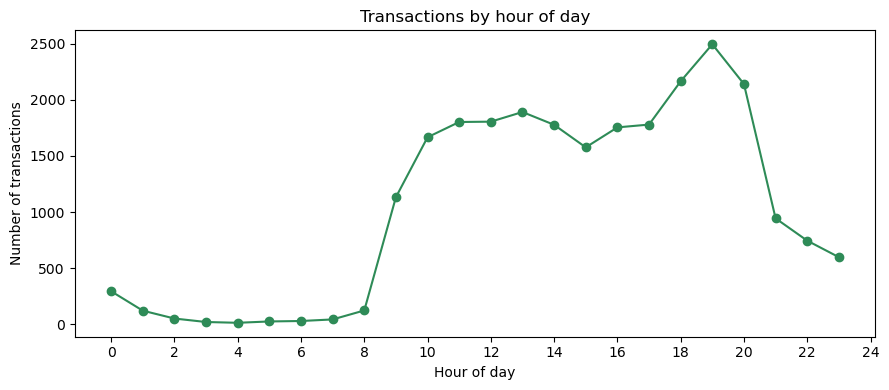

In [41]:
# When is the platform busy? Number of transactions in each hour of the day

daily_hours = df.groupby('hour_of_day').size()
daily_hours.plot(figsize=(9, 4), marker='o', color='seagreen')
plt.title("Transactions by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Number of transactions")
plt.xticks(range(0, 25, 2))
plt.tight_layout()
plt.show()

### Finding the Fraud pattern and final Reccomendations

In [42]:
total_fraud = df['is_fraud'].sum()
fraud_rate = df['is_fraud'].mean() * 100

print("Fraud Cases: ", total_fraud)
print("Fraud rate in this file:", round(fraud_rate, 2), "%")

Fraud Cases:  381
Fraud rate in this file: 1.52 %


### Fraud by Transaction type

In [43]:
t_type = df.groupby('trans_type')['is_fraud'].agg(['sum', 'mean'])
t_type['fraud_rate_pct'] = (t_type['mean'] * 100).round(2)

t_type = t_type.rename(columns={'sum': 'fraud_cases'}).drop(columns='mean')
t_type.sort_values("fraud_rate_pct", ascending=False)

,fraud_cases,fraud_rate_pct
trans_type,,
Transfer,196,8.67
Cash Out,185,2.07
Cash In,0,0.00
Debit,0,0.00
Payment,0,0.00


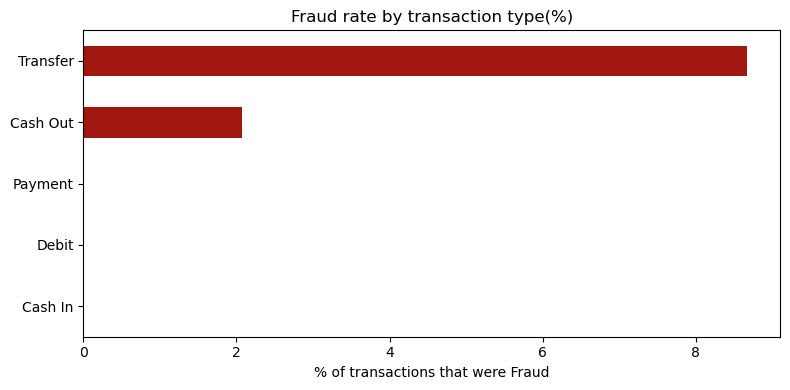

In [44]:
# Plotting the chat of Fraud rate by transaction types

rates = t_type['fraud_rate_pct'].sort_values()
rates.plot(kind='barh', color='#a01810', figsize=(8, 4))
plt.title('Fraud rate by transaction type(%)')
plt.xlabel('% of transactions that were Fraud')
plt.ylabel("")
plt.tight_layout()
plt.show()

### Fraud by time of day and by amount

In [45]:
by_band = df.groupby("time_band")["is_fraud"].agg(["sum", "mean"])
by_band["fraud_rate_pct"] = (by_band["mean"] * 100).round(2)
by_band.rename(columns={"sum": "fraud_cases"}).drop(columns="mean")

,fraud_cases,fraud_rate_pct
time_band,,
Daytime (09-20),185,0.84
Late evening (21-23),47,2.06
Night (00-08),149,20.72


In [46]:
# Typical amount: fraud '1' vs normal '0'
print(df.groupby("is_fraud")["amount"].median().round(0))

is_fraud
0     74616.0
1    416833.0
Name: amount, dtype: float64


In [47]:
# Fraud Concentrations using the 'Fraud by transaction types'

risky_types = ["Transfer", "Cash Out"]
in_risky = df.loc[df["trans_type"].isin(risky_types), "is_fraud"].sum()
print("Share of ALL fraud found in Transfer and Cash Out:", round(in_risky / total_fraud * 100, 1), "%")

Share of ALL fraud found in Transfer and Cash Out: 100.0 %


In [48]:
# Final Summary and Reccomendations

type_rate = t_type["fraud_rate_pct"]
night_rate = by_band.loc["Night (00-08)", "mean"] * 100
medians = df.groupby("is_fraud")["amount"].median()
print(f"1. WHERE: Focus on Transfer and Cash Out: {in_risky / total_fraud * 100:.0f}% of all fraud. ")
print(f"Transfer has the highest fraud rate ({type_rate['Transfer']:.1f}%).") 
print(f"Cash Out is next, with fraud rate of ({type_rate['Cash Out']:.1f}%).")
print(f"2. WHEN: The Night band (00-08) has a fraud rate of {night_rate:.1f}%.")
print(f"3. WHAT: Typical fraud is about {medians[1]:,.0f} vs {medians[0]:,.0f} for a normal transaction.")

1. WHERE: Focus on Transfer and Cash Out: 100% of all fraud. 
Transfer has the highest fraud rate (8.7%).
Cash Out is next, with fraud rate of (2.1%).
2. WHEN: The Night band (00-08) has a fraud rate of 20.7%.
3. WHAT: Typical fraud is about 416,833 vs 74,616 for a normal transaction.


In [49]:
df.to_csv("lumenpay_clean.csv", index=False)
print("Saved", df.shape[0], "rows and", df.shape[1], "columns to lumenpay_clean.csv")

Saved 25000 rows and 18 columns to lumenpay_clean.csv


In [50]:
df.head()

,hour_number,trans_type,amount,sender,old_sender_balance,new_sender_balance,receiver,old_receiver_balance,new_receiver_balance,is_fraud,is_flagged,sender_type,receiver_type,value_band,hour_of_day,day,time_band,product_line
0,398,Payment,14055.78,C1797200575,159180.00,145124.22,M1160381986,NaN,NaN,0,0,Customer,Merchant,Normal,14,17,Daytime (09-20),Merchant payments
1,182,Cash Out,180339.33,C700363449,5318.00,0.00,C1953400814,NaN,180339.33,0,0,Customer,Customer,Normal,14,8,Daytime (09-20),Cash services
2,134,Cash In,30487.29,C712454949,12380.00,42867.29,C603302194,2405494.70,2375007.41,0,0,Customer,Customer,Normal,14,6,Daytime (09-20),Cash services
3,401,Payment,26549.72,C648332042,0.00,0.00,M361318237,NaN,NaN,0,0,Customer,Merchant,Normal,17,17,Daytime (09-20),Merchant payments
4,331,Cash In,486453.98,C59362593,5894087.86,6380541.85,C574749985,3917145.47,3430691.48,0,0,Customer,Customer,High value,19,14,Daytime (09-20),Cash services


### Top 10 Senders

In [68]:
# To print the top 10 senders whose transactions experienced fraud.

top_send = df.groupby(['sender', 'product_line' ])[['is_fraud', 'amount' ]].sum()
top10_send = top_send.nlargest(10, ['is_fraud', 'amount']).reset_index()

print(top10_send)

        sender      product_line  is_fraud      amount
0  C1045409609  Person to person         1  10000000.0
1  C1474911553     Cash services         1  10000000.0
2  C1551381510  Person to person         1  10000000.0
3  C1577276514     Cash services         1  10000000.0
4  C1660275627  Person to person         1  10000000.0
5  C1877358148     Cash services         1  10000000.0
6  C2037845109  Person to person         1  10000000.0
7  C2050703310     Cash services         1  10000000.0
8  C2068007279     Cash services         1  10000000.0
9  C2074382913  Person to person         1  10000000.0


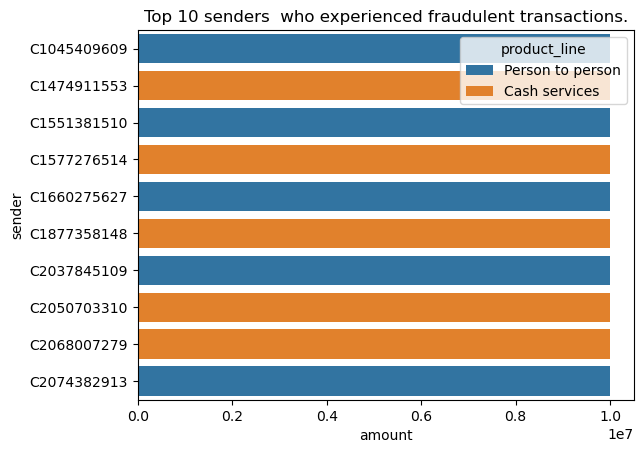

In [72]:
sns.barplot(data=top10_send, y='sender', x='amount', hue='product_line')
plt.title('Top 10 senders  who experienced fraudulent transactions.');